# Chapter 8 - Final Evaluation and Recommendation

This notebook opens the test split once and evaluates the frozen models A, B, C and the selected ensemble BC. Chapter 6 saved validation probabilities but not model objects, so the three tuned configurations are refit on the training split with seed 42 and checked against the Chapter 6 validation probabilities before the test split is read.

No hyperparameter, threshold or ensemble weight is changed after the test predictions are produced.


In [1]:
# 0. Setup: imports, portable paths and fixed seed
from pathlib import Path
import json
import pickle
import sys
import time

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score,
                             brier_score_loss, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve,
                             precision_recall_curve)
from xgboost import XGBClassifier

BASE_DIR = Path("..")
DATA_DIR = BASE_DIR / "data_processed"
MODEL_DIR = DATA_DIR / "model_results"
PRED_DIR = DATA_DIR / "predictions"
OUT_DIR = BASE_DIR / "outputs" / "chapter_08"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CH7_MANIFEST = json.loads(
    (BASE_DIR / "outputs" / "chapter_07" / "run_manifest.json").read_text(encoding="utf-8")
)
FROZEN_FINAL_MODEL = CH7_MANIFEST["final_model"]

TARGET = "default.payment.next.month"
ID_COL = "ID"
SEED = 42
MODEL_COLORS = {"A": "#4C72B0", "B": "#DD8452", "C": "#55A868", "BC": "#8172B3"}

if sklearn.__version__ != "1.9.1":
    raise RuntimeError(f"This notebook requires scikit-learn 1.9.1, found {sklearn.__version__}")

np.random.seed(SEED)
pd.set_option("display.width", 150)
print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | "
      f"pandas {pd.__version__} | numpy {np.__version__} | xgboost {xgboost.__version__}")


Python 3.11.9 | scikit-learn 1.9.1 | pandas 3.0.6 | numpy 2.4.6 | xgboost 3.2.0


In [2]:
# 1. Load the frozen specification, configurations, thresholds and development splits.
spec = json.loads((DATA_DIR / "preprocessing_spec.json").read_text(encoding="utf-8"))
best = json.loads((MODEL_DIR / "best_configs.json").read_text(encoding="utf-8"))
thresholds = pd.read_csv(
    BASE_DIR / "outputs" / "chapter_07" / "table07_03_selected_thresholds.csv"
).set_index("Model")["Threshold"].to_dict()

FEATURES = spec["feature_sets"][spec["selected_set"]]
train = pd.read_csv(DATA_DIR / "train.csv")
val = pd.read_csv(DATA_DIR / "val.csv")
frozen_val = pd.read_csv(PRED_DIR / "ch06_tuned_val.csv")
frozen_ensemble = pd.read_csv(PRED_DIR / "ch07_ensemble_val.csv")

assert len(train) == 20975, len(train)
assert len(val) == 4495, len(val)
assert len(FEATURES) == 23, len(FEATURES)
assert set(FEATURES).issubset(train.columns)
assert set(FEATURES).issubset(val.columns)
assert train[TARGET].isin([0, 1]).all()
assert val[TARGET].isin([0, 1]).all()
assert set(thresholds) >= {"A", "B", "C", "BC"}

print(f"Training rows   : {len(train):,}")
print(f"Validation rows : {len(val):,}")
print(f"Features        : {len(FEATURES)}")
print("Frozen thresholds:", {name: thresholds[name] for name in ["A", "B", "C", "BC"]})


Training rows   : 20,975
Validation rows : 4,495
Features        : 23
Frozen thresholds: {'A': 0.56, 'B': 0.57, 'C': 0.58, 'BC': 0.59}


In [3]:
# 2. Refit the three frozen configurations on the training split.
FIXED = {
    "A": {"solver": "lbfgs", "max_iter": 1000, "fit_intercept": True,
          "tol": 1e-4, "random_state": SEED},
    "B": {"bootstrap": True, "criterion": "gini", "oob_score": False,
          "warm_start": False, "max_samples": None, "max_leaf_nodes": None,
          "min_weight_fraction_leaf": 0.0, "min_impurity_decrease": 0.0,
          "ccp_alpha": 0.0, "n_jobs": -1, "random_state": SEED},
    "C": {"booster": "gbtree", "objective": "binary:logistic",
          "tree_method": "hist", "eval_metric": "auc", "n_jobs": -1,
          "random_state": SEED, "reg_alpha": 0, "colsample_bylevel": 1,
          "colsample_bynode": 1, "max_delta_step": 0},
}

models = {
    "A": LogisticRegression(**FIXED["A"], **best["A"]["params"]),
    "B": RandomForestClassifier(**FIXED["B"], **best["B"]["params"]),
    "C": XGBClassifier(**FIXED["C"], **best["C"]["params"]),
}

fit_times = {}
for name, model in models.items():
    start = time.perf_counter()
    model.fit(train[FEATURES], train[TARGET])
    fit_times[name] = time.perf_counter() - start
    print(f"Model {name}: fitted in {fit_times[name]:.4f} s")


Model A: fitted in 0.1194 s


Model B: fitted in 2.5425 s


Model C: fitted in 0.4399 s


In [4]:
# 3. Reproduce the Chapter 6 validation probabilities before opening the test split.
val_proba = {name: model.predict_proba(val[FEATURES])[:, 1]
             for name, model in models.items()}
val_proba["BC"] = (val_proba["B"] + val_proba["C"]) / 2

for name, column in [("A", "p_A"), ("B", "p_B"), ("C", "p_C")]:
    difference = np.max(np.abs(val_proba[name] - frozen_val[column].to_numpy()))
    print(f"Model {name}: max abs difference = {difference:.2e}")
    assert difference < 1e-6, (name, difference)

ensemble_difference = np.max(np.abs(val_proba["BC"] - frozen_ensemble["p_BC"].to_numpy()))
print(f"BC: max abs difference = {ensemble_difference:.2e}")
assert ensemble_difference < 1e-6, ensemble_difference
print("Validation probabilities reproduced.")


Model A: max abs difference = 1.11e-16


Model B: max abs difference = 3.33e-16
Model C: max abs difference = 2.98e-08
BC: max abs difference = 1.49e-08
Validation probabilities reproduced.


In [5]:
# 4. Open the test split once and produce the four probability columns.
test = pd.read_csv(DATA_DIR / "test.csv")

assert len(test) == 4495, len(test)
assert set(FEATURES).issubset(test.columns)
assert test[TARGET].isin([0, 1]).all()
assert test[ID_COL].is_unique

test_proba = {name: model.predict_proba(test[FEATURES])[:, 1]
              for name, model in models.items()}
test_proba["BC"] = (test_proba["B"] + test_proba["C"]) / 2

for name, proba in test_proba.items():
    assert np.all((proba >= 0) & (proba <= 1)), name

test_predictions = pd.DataFrame({
    ID_COL: test[ID_COL],
    "p_A": test_proba["A"],
    "p_B": test_proba["B"],
    "p_C": test_proba["C"],
    "p_BC": test_proba["BC"],
})
test_predictions.to_csv(PRED_DIR / "ch08_test_probabilities.csv", index=False)

print(f"Test rows        : {len(test):,}")
print(f"Test default rate: {test[TARGET].mean():.4f}")
print(f"Saved            : {PRED_DIR / 'ch08_test_probabilities.csv'}")
display(test_predictions.describe().round(4))


Test rows        : 4,495
Test default rate: 0.2214
Saved            : ..\data_processed\predictions\ch08_test_probabilities.csv


,ID,p_A,p_B,p_C,p_BC
count,4495.0000,4495.0000,4495.0000,4495.0000,4495.0000
mean,15046.7444,0.4478,0.4178,0.4144,0.4161
std,8716.1083,0.1923,0.2062,0.2274,0.2159
min,2.0000,0.0609,0.0854,0.0424,0.0685
25%,7527.5000,0.3188,0.2669,0.2452,0.2566
50%,14931.0000,0.4104,0.3566,0.3580,0.3564
75%,22655.0000,0.5565,0.5162,0.5449,0.5276
max,30000.0000,0.9985,0.9589,0.9587,0.9580


In [6]:
# 5. Test performance and generalisation table.
train_proba = {name: model.predict_proba(train[FEATURES])[:, 1]
               for name, model in models.items()}
train_proba["BC"] = (train_proba["B"] + train_proba["C"]) / 2

def metrics_at_threshold(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    tp = int(((pred == 1) & (y_true == 1)).sum())
    fp = int(((pred == 1) & (y_true == 0)).sum())
    tn = int(((pred == 0) & (y_true == 0)).sum())
    fn = int(((pred == 0) & (y_true == 1)).sum())

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    accuracy = (tp + tn) / (tp + fp + tn + fn)

    return {"Accuracy": accuracy, "Precision": precision, "Recall": recall,
            "F1": f1, "TP": tp, "FP": fp, "TN": tn, "FN": fn}

y_test = test[TARGET].to_numpy()
rows = []
for name in ["A", "B", "C", "BC"]:
    threshold = float(thresholds[name])
    test_metrics = metrics_at_threshold(y_test, test_proba[name], threshold)
    rows.append({
        "Model": name,
        "Train AUC": roc_auc_score(train[TARGET], train_proba[name]),
        "Validation AUC": roc_auc_score(val[TARGET], val_proba[name]),
        "Test AUC": roc_auc_score(y_test, test_proba[name]),
        "Test PR-AUC": average_precision_score(y_test, test_proba[name]),
        "Test F1": test_metrics["F1"],
        "Brier": brier_score_loss(y_test, test_proba[name]),
    })

table_08_01 = pd.DataFrame(rows).set_index("Model")

# 5b. Platt calibration fitted on validation, applied to the test probabilities.
# Class weighting lifts the mean predicted probability, so the raw Brier score is
# not comparable with a base-rate forecast. The sigmoid is fitted on validation
# only; the test split is still used once, for the final score.
calibrated = {}
for name in ["A", "B", "C", "BC"]:
    calibrator = LogisticRegression(C=1e6, max_iter=1000)
    calibrator.fit(val_proba[name].reshape(-1, 1), val[TARGET])
    calibrated[name] = calibrator.predict_proba(
        test_proba[name].reshape(-1, 1))[:, 1]

table_08_01["Brier (calibrated)"] = {
    name: brier_score_loss(y_test, calibrated[name]) for name in table_08_01.index
}
table_08_01.to_csv(OUT_DIR / "table08_01_test_performance.csv")
display(table_08_01.round(4))


,Train AUC,Validation AUC,Test AUC,Test PR-AUC,Test F1,Brier,Brier (calibrated)
Model,,,,,,,
A,0.7542,0.7457,0.7377,0.5002,0.5024,0.1997,0.1444
B,0.8678,0.7777,0.7677,0.5479,0.5223,0.1777,0.1370
C,0.8464,0.7808,0.7733,0.5499,0.5311,0.1776,0.1361
BC,0.8584,0.7805,0.7718,0.5510,0.5270,0.1771,0.1363


,TP,FN,FP,TN,Precision,Recall,F1
Model,,,,,,,
A,528,467,579,2921,0.4770,0.5307,0.5024
B,503,492,428,3072,0.5403,0.5055,0.5223
C,525,470,457,3043,0.5346,0.5276,0.5311
BC,507,488,422,3078,0.5457,0.5095,0.5270


B/C validation correlation: 0.9808


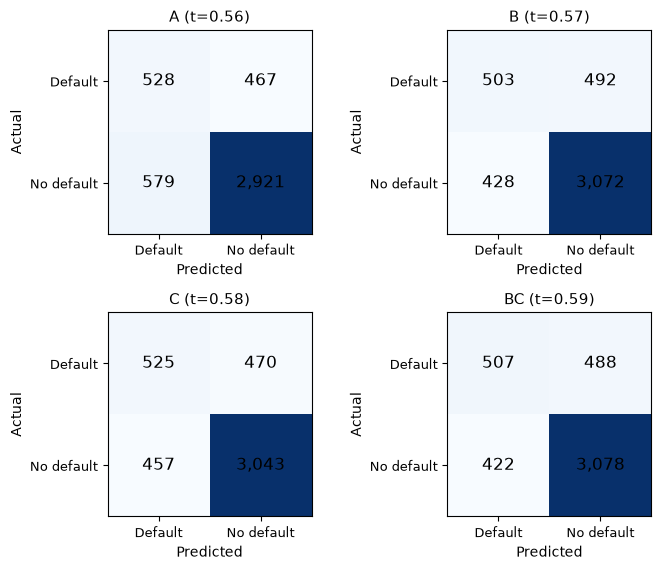

In [7]:
# 6. Confusion matrices at the frozen thresholds, and the correlation
# between the B and C validation predictions.
rows = []
for name in ["A", "B", "C", "BC"]:
    metrics = metrics_at_threshold(y_test, test_proba[name], thresholds[name])
    rows.append({
        "Model": name,
        "TP": metrics["TP"],
        "FN": metrics["FN"],
        "FP": metrics["FP"],
        "TN": metrics["TN"],
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"],
        "F1": metrics["F1"],
    })

table_08_05 = pd.DataFrame(rows).set_index("Model")
table_08_05.to_csv(OUT_DIR / "table08_05_confusion.csv")
display(table_08_05.round(4))

bc_corr = np.corrcoef(val_proba["B"], val_proba["C"])[0, 1]
print(f"B/C validation correlation: {bc_corr:.4f}")

# 6b. Four 2x2 confusion matrices at the frozen thresholds.
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.8))
for ax, name in zip(axes.ravel(), ["A", "B", "C", "BC"]):
    metrics = table_08_05.loc[name]
    matrix = np.array([[metrics["TP"], metrics["FN"]],
                       [metrics["FP"], metrics["TN"]]], dtype=int)
    ax.imshow(matrix, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{matrix[i, j]:,}",
                    ha="center", va="center", fontsize=12)
    ax.set_title(f"{name} (t={thresholds[name]:.2f})", fontsize=11)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Default", "No default"], fontsize=9)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Default", "No default"], fontsize=9)
    ax.set_xlabel("Predicted", fontsize=10)
    ax.set_ylabel("Actual", fontsize=10)

fig.tight_layout()
fig.savefig(OUT_DIR / "fig_8_confusion.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
# 6. Computational and deployment profile.
def inference_ms(model, frame, repeats=3):
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        model.predict_proba(frame[FEATURES])
        times.append(time.perf_counter() - start)
    return float(np.median(times) * 1000 / len(frame) * 1000)

inference_times = {
    "A": inference_ms(models["A"], test),
    "B": inference_ms(models["B"], test),
    "C": inference_ms(models["C"], test),
}

bc_times = []
for _ in range(3):
    start = time.perf_counter()
    _ = (models["B"].predict_proba(test[FEATURES])[:, 1]
         + models["C"].predict_proba(test[FEATURES])[:, 1]) / 2
    bc_times.append(time.perf_counter() - start)
inference_times["BC"] = float(np.median(bc_times) * 1000 / len(test) * 1000)

model_sizes = {name: len(pickle.dumps(model)) / (1024 ** 2)
               for name, model in models.items()}
model_sizes["BC"] = model_sizes["B"] + model_sizes["C"]

interpretability = {"A": "High", "B": "Medium", "C": "Medium", "BC": "Medium"}
deployment = {
    "A": "Smallest and fastest, linear",
    "B": "Largest, slower inference",
    "C": "Compact boosted trees",
    "BC": "Two models, double inference",
}

rows = []
for name in ["A", "B", "C", "BC"]:
    fit_time = fit_times["B"] + fit_times["C"] if name == "BC" else fit_times[name]
    rows.append({
        "Model": name,
        "Fit time (s)": fit_time,
        "Inference (ms/1,000)": inference_times[name],
        "Serialized size (MB)": model_sizes[name],
        "Interpretability": interpretability[name],
        "Deployment note": deployment[name],
    })

table_08_02 = pd.DataFrame(rows).set_index("Model")
table_08_02.to_csv(OUT_DIR / "table08_02_efficiency.csv")
display(table_08_02.round(4))


,Fit time (s),"Inference (ms/1,000)",Serialized size (MB),Interpretability,Deployment note
Model,,,,,
A,0.1194,0.3246,0.0012,High,"Smallest and fastest, linear"
B,2.5425,32.2832,37.6535,Medium,"Largest, slower inference"
C,0.4399,1.5748,0.7884,Medium,Compact boosted trees
BC,2.9824,44.0274,38.4419,Medium,"Two models, double inference"


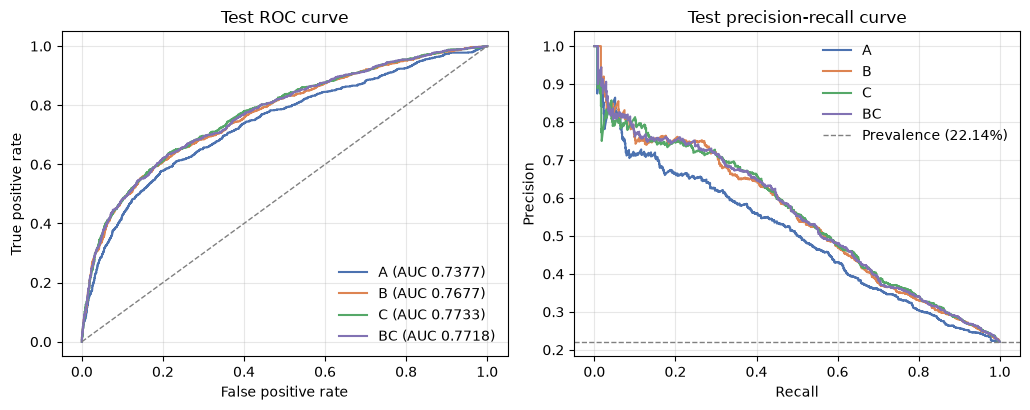

In [9]:
# 7. Test ROC and precision-recall curves.
fig, axes = plt.subplots(1, 2, figsize=(10.4, 4.2))
prevalence = y_test.mean()

for name in ["A", "B", "C", "BC"]:
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    precision, recall, _ = precision_recall_curve(y_test, test_proba[name])
    auc = table_08_01.loc[name, "Test AUC"]
    axes[0].plot(fpr, tpr, linewidth=1.5, color=MODEL_COLORS[name],
                 label=f"{name} (AUC {auc:.4f})")
    axes[1].plot(recall, precision, linewidth=1.5,
                 color=MODEL_COLORS[name], label=name)

axes[0].plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1)
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("Test ROC curve")
axes[0].legend(frameon=False, loc="lower right")

axes[1].axhline(prevalence, linestyle="--", color="grey", linewidth=1,
                label=f"Prevalence ({prevalence:.2%})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Test precision-recall curve")
axes[1].legend(frameon=False, loc="upper right")

for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_8_roc_pr.png", dpi=300)
plt.show()


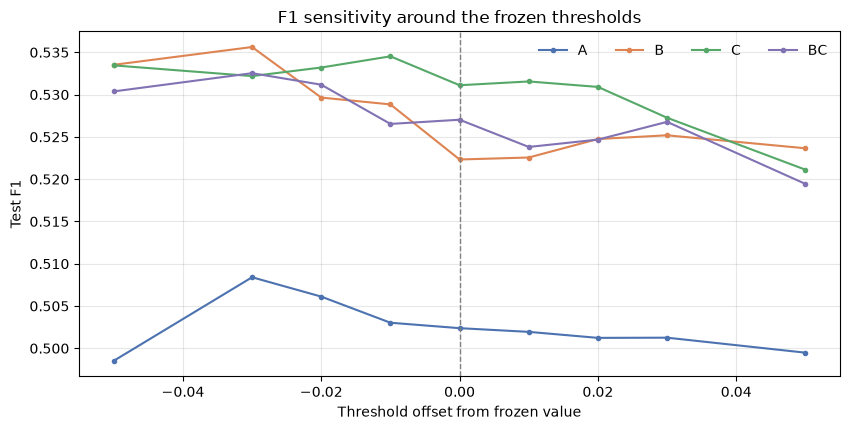

In [10]:
# 8. F1 sensitivity around the frozen thresholds.
offsets = [-0.05, -0.03, -0.02, -0.01, 0.0, 0.01, 0.02, 0.03, 0.05]
sensitivity_rows = []

for name in ["A", "B", "C", "BC"]:
    base = float(thresholds[name])
    for offset in offsets:
        threshold = round(float(np.clip(base + offset, 0.01, 0.99)), 2)
        f1 = metrics_at_threshold(y_test, test_proba[name], threshold)["F1"]
        sensitivity_rows.append({"Model": name, "Offset": offset,
                                 "Threshold": threshold, "F1": f1})

table_08_03 = pd.DataFrame(sensitivity_rows)
table_08_03.to_csv(OUT_DIR / "table08_03_threshold_sensitivity.csv", index=False)

fig, ax = plt.subplots(figsize=(8.6, 4.4))
for name in ["A", "B", "C", "BC"]:
    subset = table_08_03[table_08_03["Model"] == name]
    ax.plot(subset["Offset"], subset["F1"], marker="o", markersize=3,
            linewidth=1.5, color=MODEL_COLORS[name], label=name)

ax.axvline(0, linestyle="--", color="grey", linewidth=1)
ax.set_xlabel("Threshold offset from frozen value")
ax.set_ylabel("Test F1")
ax.set_title("F1 sensitivity around the frozen thresholds")
ax.grid(alpha=0.3)
ax.legend(frameon=False, ncol=4)
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_8_threshold_sensitivity.png", dpi=300)
plt.show()


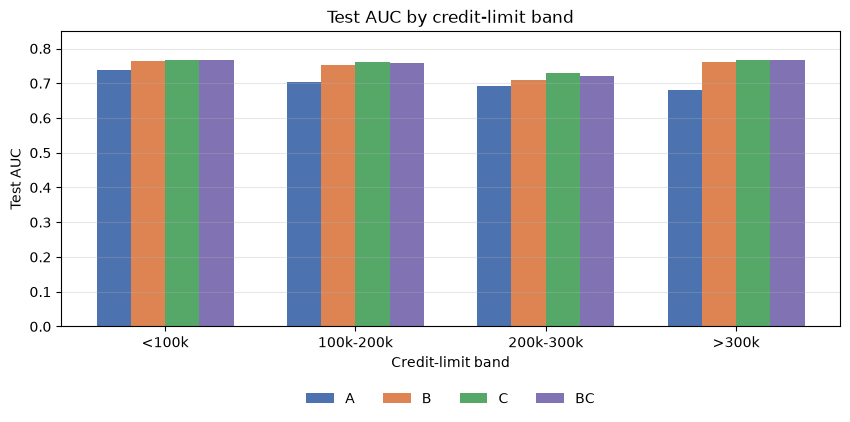

,Band,Rows,Defaults,AUC A,AUC B,AUC C,AUC BC
0,<100k,1855,551,0.7368,0.7639,0.7679,0.7667
1,100k-200k,1182,213,0.7050,0.7533,0.7615,0.7594
2,200k-300k,759,124,0.6911,0.7105,0.7283,0.7214
3,>300k,699,107,0.6800,0.7627,0.7659,0.7678


In [11]:
# 9. Test AUC by credit-limit band.
scaler_params = pd.read_csv(DATA_DIR / "scaler_params.csv").set_index("feature")
limit_mean = float(scaler_params.loc["LIMIT_BAL", "mean"])
limit_scale = float(scaler_params.loc["LIMIT_BAL", "scale"])
raw_limit = np.expm1(test["LIMIT_BAL"].to_numpy() * limit_scale + limit_mean)
bands = pd.cut(raw_limit, bins=[0, 100000, 200000, 300000, np.inf],
               labels=["<100k", "100k-200k", "200k-300k", ">300k"], right=False)

band_rows = []
for band in bands.categories:
    mask = np.asarray(bands == band)
    row = {"Band": band, "Rows": int(mask.sum()), "Defaults": int(y_test[mask].sum())}
    for name in ["A", "B", "C", "BC"]:
        if len(np.unique(y_test[mask])) == 2:
            row[f"AUC {name}"] = roc_auc_score(y_test[mask], test_proba[name][mask])
        else:
            row[f"AUC {name}"] = np.nan
    band_rows.append(row)

table_08_04 = pd.DataFrame(band_rows)
table_08_04.to_csv(OUT_DIR / "table08_04_limit_bands.csv", index=False)

fig, ax = plt.subplots(figsize=(8.6, 4.4))
x = np.arange(len(table_08_04))
width = 0.18
for position, name in enumerate(["A", "B", "C", "BC"]):
    ax.bar(x + (position - 1.5) * width, table_08_04[f"AUC {name}"],
           width=width, color=MODEL_COLORS[name], label=name)

ax.set_xticks(x)
ax.set_xticklabels(table_08_04["Band"])
ax.set_xlabel("Credit-limit band")
ax.set_ylabel("Test AUC")
ax.set_title("Test AUC by credit-limit band")
ax.set_ylim(0, 0.85)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fig.tight_layout()
fig.savefig(OUT_DIR / "fig_8_limit_bands.png", dpi=300, bbox_inches="tight")
plt.show()

display(table_08_04.round(4))


In [12]:
# 10. Report the model that Chapter 7 fixed on validation data.
# Test results are reported for evaluation, not used for selection.
recommended = FROZEN_FINAL_MODEL
print(f"Pre-selected model: {recommended}")
print(f"Test AUC: {table_08_01.loc[recommended, 'Test AUC']:.4f}")
print(f"Test F1:  {table_08_01.loc[recommended, 'Test F1']:.4f}")


Pre-selected model: C
Test AUC: 0.7733
Test F1:  0.5311


In [13]:
# 11. Save the run manifest.
manifest = {
    "chapter": "08_final_evaluation",
    "random_seed": SEED,
    "data": {
        "train_rows": int(len(train)),
        "validation_rows": int(len(val)),
        "test_rows": int(len(test)),
        "test_positive_rate": float(test[TARGET].mean()),
        "test_split_used": True,
    },
    "protocol": {
        "refit_frozen_configs": True,
        "validation_reproduction_tolerance": 1e-6,
        "thresholds": {name: float(thresholds[name]) for name in ["A", "B", "C", "BC"]},
        "primary_metric": "validation_roc_auc",
        "selection_source": "bank/outputs/chapter_07/run_manifest.json",
        "selected_model": recommended,
        "test_role": "final_evaluation_only",
        "test_used_for_selection": False,
    },
    "recommended_model": recommended,
    "environment": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "xgboost": xgboost.__version__,
        "matplotlib": matplotlib.__version__,
    },
    "artifacts": {
        "test_probabilities": "bank/data_processed/predictions/ch08_test_probabilities.csv",
        "table_08_01": "bank/outputs/chapter_08/table08_01_test_performance.csv",
        "table_08_02": "bank/outputs/chapter_08/table08_02_efficiency.csv",
        "table_08_03": "bank/outputs/chapter_08/table08_03_threshold_sensitivity.csv",
        "table_08_04": "bank/outputs/chapter_08/table08_04_limit_bands.csv",
        "figure_08_02": "bank/outputs/chapter_08/fig_8_roc_pr.png",
        "figure_08_05": "bank/outputs/chapter_08/fig_8_threshold_sensitivity.png",
        "figure_08_07": "bank/outputs/chapter_08/fig_8_limit_bands.png",
    },
}
(OUT_DIR / "run_manifest.json").write_text(
    json.dumps(manifest, indent=2), encoding="utf-8")
print("Saved", OUT_DIR / "run_manifest.json")


Saved ..\outputs\chapter_08\run_manifest.json


## Summary

The notebook has evaluated A, B, C and BC on the test split with the frozen thresholds and the pre-declared recommendation rule. The test predictions and aggregate results are saved for the Chapter 8 report.
